# 03 — Explainable AI: Examining Model Predictions with Grad-CAM++

In Notebook 02, I compared EfficientNetB3 and ConvNeXt-Tiny on benign and adenocarcinoma colon tissue. Although both models achieved high accuracy, I wanted to examine which image regions influenced their predictions. I used Grad-CAM++ to generate heatmaps and evaluated the highlighted regions using confidence-based faithfulness measures and masking controls.

I loaded the fine-tuned models from Notebook 02 and used the dataset partitions created in Notebook 01. I first checked the attribution implementation, then evaluated a balanced set of validation images at two retention thresholds.

In [4]:

import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

# Reproducibility
SEED = 40
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.20.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 1. Environment and Saved Project Files

I checked the Kaggle environment and attached files before beginning the analysis. I reused the models saved in Notebook 02 so I could evaluate their explanations without retraining them.

In [5]:

from pathlib import Path

input_dir = Path("/kaggle/input")

print("=== ZIP files ===")
for path in input_dir.rglob("*.zip"):
    print(path)

print("\n=== Saved models ===")
for path in input_dir.rglob("*.keras"):
    print(path)

print("\n=== Dataset splits ===")
for path in input_dir.rglob("*.csv"):
    print(path)


=== ZIP files ===

=== Saved models ===
/kaggle/input/datasets/educatedfish808/colon-project-results/baseline_cnn.keras
/kaggle/input/datasets/educatedfish808/colon-project-results/models/effnet_stage1_best.keras
/kaggle/input/datasets/educatedfish808/colon-project-results/models/convnext_stage1_best.keras
/kaggle/input/datasets/educatedfish808/colon-project-results/models/convnext_finetuned_best.keras
/kaggle/input/datasets/educatedfish808/colon-project-results/models/effnet_finetuned_best.keras

=== Dataset splits ===
/kaggle/input/datasets/educatedfish808/colon-project-results/final_model_comparison.csv
/kaggle/input/notebooks/educatedfish808/01-colon-histopathology-eda/splits/validation.csv
/kaggle/input/notebooks/educatedfish808/01-colon-histopathology-eda/splits/train.csv
/kaggle/input/notebooks/educatedfish808/01-colon-histopathology-eda/splits/test.csv


### Loading the Fine-Tuned Models

I loaded the saved EfficientNetB3 and ConvNeXt-Tiny models without recompiling them, since I only needed inference and gradients. I also checked their output shapes before generating explanations.

In [6]:

from pathlib import Path
import tensorflow as tf
import pandas as pd
import numpy as np

# Paths to saved model files
MODEL_DIR = Path(
    "/kaggle/input/datasets/educatedfish808/colon-project-results/models"
)

# Load our final fine-tuned models
effnet_model = tf.keras.models.load_model(
    MODEL_DIR / "effnet_finetuned_best.keras",
    compile=False
)

convnext_model = tf.keras.models.load_model(
    MODEL_DIR / "convnext_finetuned_best.keras",
    compile=False
)

print("EfficientNetB3 loaded successfully.")
print("ConvNeXt-Tiny loaded successfully.")

print("\nEfficientNetB3 output shape:", effnet_model.output_shape)
print("ConvNeXt-Tiny output shape:", convnext_model.output_shape)


I0000 00:00:1792424967.396230      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792424967.400126      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


EfficientNetB3 loaded successfully.
ConvNeXt-Tiny loaded successfully.

EfficientNetB3 output shape: (None, 2)
ConvNeXt-Tiny output shape: (None, 2)


## 2. Test Images and Initial Visual Inspection

I loaded the test partition and selected examples from each class to inspect the images before generating explanations. These examples were only used for visual inspection, not as a representative evaluation of the full dataset.

In [7]:

SPLIT_DIR = Path(
    "/kaggle/input/notebooks/educatedfish808/01-colon-histopathology-eda/splits"
)

test_df = pd.read_csv(SPLIT_DIR / "test.csv")

print("Test images:", len(test_df))
print("\nClass distribution:")
print(test_df["labels"].value_counts())

print("\nFirst few rows:")
display(test_df[["filepaths", "labels"]].head())

print("\nFirst image exists:",
      Path(test_df["filepaths"].iloc[0]).exists())


Test images: 963

Class distribution:
labels
adenocarcinoma    483
benign            480
Name: count, dtype: int64

First few rows:


,filepaths,labels
0,/kaggle/input/datasets/andrewmvd/lung-and-colo...,adenocarcinoma
1,/kaggle/input/datasets/andrewmvd/lung-and-colo...,adenocarcinoma
2,/kaggle/input/datasets/andrewmvd/lung-and-colo...,adenocarcinoma
3,/kaggle/input/datasets/andrewmvd/lung-and-colo...,adenocarcinoma
4,/kaggle/input/datasets/andrewmvd/lung-and-colo...,adenocarcinoma



First image exists: True


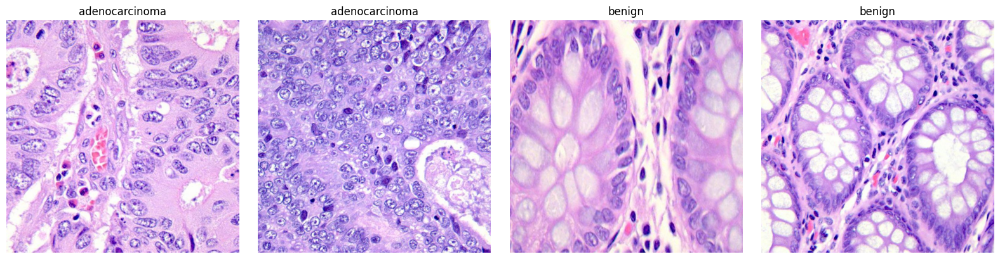

In [8]:

from PIL import Image
import matplotlib.pyplot as plt

# Select 2 images from each class
sample_df = (
    test_df.groupby("labels", group_keys=False)
    .sample(n=2, random_state=40)
    .reset_index(drop=True)
)

# Verify files exist
for filepath in sample_df["filepaths"]:
    assert Path(filepath).exists(), f"Image not found: {filepath}"

# Display the selected images
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, (_, row) in zip(axes, sample_df.iterrows()):
    with Image.open(row["filepaths"]) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(row["labels"])
    ax.axis("off")

plt.tight_layout()
plt.show()


## 3. Inspecting the Models and Gradients

I inspected the models' layers and checked whether gradients could be calculated through their classification heads. This was important because a heatmap could appear reasonable even if the underlying gradient calculation was incorrect.

In [9]:

def inspect_last_layers(backbone, n=15):
    print(f"\n{backbone.name}")
    print("-" * 70)

    for layer in backbone.layers[-n:]:
        print(
            f"{layer.name:45s}",
            f"{layer.__class__.__name__:25s}"
        )


effnet_base = effnet_model.get_layer("efficientnetb3")
convnext_base = convnext_model.get_layer("convnext_tiny")

inspect_last_layers(effnet_base)
inspect_last_layers(convnext_base)



efficientnetb3
----------------------------------------------------------------------
block7b_dwconv                                DepthwiseConv2D          
block7b_bn                                    BatchNormalization       
block7b_activation                            Activation               
block7b_se_squeeze                            GlobalAveragePooling2D   
block7b_se_reshape                            Reshape                  
block7b_se_reduce                             Conv2D                   
block7b_se_expand                             Conv2D                   
block7b_se_excite                             Multiply                 
block7b_project_conv                          Conv2D                   
block7b_project_bn                            BatchNormalization       
block7b_drop                                  Dropout                  
block7b_add                                   Add                      
top_conv                                      Con

In [10]:

def load_image_for_xai(filepath):
    with Image.open(filepath) as img:
        img = img.convert("RGB")
        img = img.resize((224, 224))
        image_array = np.asarray(img, dtype=np.float32)

    # Match the 0-1 scaling used during training
    image_array = image_array / 255.0

    # Add batch dimension: (1, 224, 224, 3)
    return tf.convert_to_tensor(
        image_array[None, ...],
        dtype=tf.float32
    )


# Select our first image
image_path = sample_df["filepaths"].iloc[0]
image_tensor = load_image_for_xai(image_path)

print("Image tensor shape:", image_tensor.shape)
print("Actual label:", sample_df["labels"].iloc[0])


Image tensor shape: (1, 224, 224, 3)
Actual label: adenocarcinoma


In [11]:

def inspect_xai_gradients(model, backbone, image_tensor):

    # The backbone is nested inside our full model.
    # Layer 1 performs input rescaling.
    # Layers 3 onward form the classification head.

    with tf.GradientTape() as tape:

        x = model.layers[1](image_tensor)

        feature_maps = backbone(x, training=False)
        tape.watch(feature_maps)

        x = feature_maps

        for layer in model.layers[3:]:
            x = layer(x, training=False)

        predictions = x

        # Explain the model's predicted class
        predicted_class = tf.argmax(predictions[0])
        class_score = tf.gather(
            predictions[0],
            predicted_class
        )

    gradients = tape.gradient(
        class_score,
        feature_maps
    )

    return predictions, feature_maps, gradients


predictions, feature_maps, gradients = inspect_xai_gradients(
    effnet_model,
    effnet_base,
    image_tensor
)

print("Predictions:", predictions.numpy())
print("Feature maps:", feature_maps.shape)
print("Gradients:", gradients.shape)
print("Gradients available:", gradients is not None)

if gradients is not None:
    print(
        "Gradients are finite:",
        bool(tf.reduce_all(tf.math.is_finite(gradients)))
    )

    print(
        "Maximum absolute gradient:",
        float(tf.reduce_max(tf.abs(gradients)))
    )

# Verify that our gradient pipeline reproduces
# the original full model's predictions.
direct_predictions = effnet_model(
    image_tensor,
    training=False
)

np.testing.assert_allclose(
    predictions.numpy(),
    direct_predictions.numpy(),
    rtol=1e-5,
    atol=1e-6
)

print("Predictions match the saved model.")


Predictions: [[9.994894e-01 5.105552e-04]]
Feature maps: (1, 7, 7, 1536)
Gradients: (1, 7, 7, 1536)
Gradients available: True
Gradients are finite: True
Maximum absolute gradient: 6.929593382665189e-06
Predictions match the saved model.


### Exploratory Attribution Approximation

I initially tested an approximate Grad-CAM++ calculation based on powers of first-order gradients to check the heatmap shapes and visualizations. I kept this exploratory step separate from the revised implementation used in the quantitative analysis.

In [12]:

def gradcampp_approx(model, backbone, image_tensor):
    # Get predictions, feature maps, and gradients
    predictions, feature_maps, gradients = inspect_xai_gradients(
        model, backbone, image_tensor
    )

    # Remove batch dimension
    activations = feature_maps[0]
    grads = gradients[0]

    # Approximate Grad-CAM++ spatial weighting.
    # This uses powers of first-order gradients rather
    # than explicitly computing higher-order derivatives.

    grads_sq = tf.square(grads)
    grads_cube = grads_sq * grads

    sum_activations = tf.reduce_sum(
        activations, axis=(0, 1), keepdims=True
    )

    denominator = (
        2.0 * grads_sq
        + sum_activations * grads_cube
    )

    # Avoid division by zero without overwhelming
    # the very small gradient values.
    alphas = tf.math.divide_no_nan(
        grads_sq, denominator
    )

    # Only positive gradient contributions
    positive_grads = tf.nn.relu(grads)

    # Calculate channel weights
    weights = tf.reduce_sum(
        alphas * positive_grads,
        axis=(0, 1)
    )

    # Weighted combination of feature maps
    heatmap = tf.reduce_sum(
        activations * weights,
        axis=-1
    )

    heatmap = tf.nn.relu(heatmap)

    # Normalize to [0, 1]
    maximum = tf.reduce_max(heatmap)
    heatmap = tf.math.divide_no_nan(heatmap, maximum)

    return heatmap.numpy(), predictions.numpy()


Heatmap shape: (7, 7)
Heatmap minimum: 0.0
Heatmap maximum: 1.0
All values finite: True


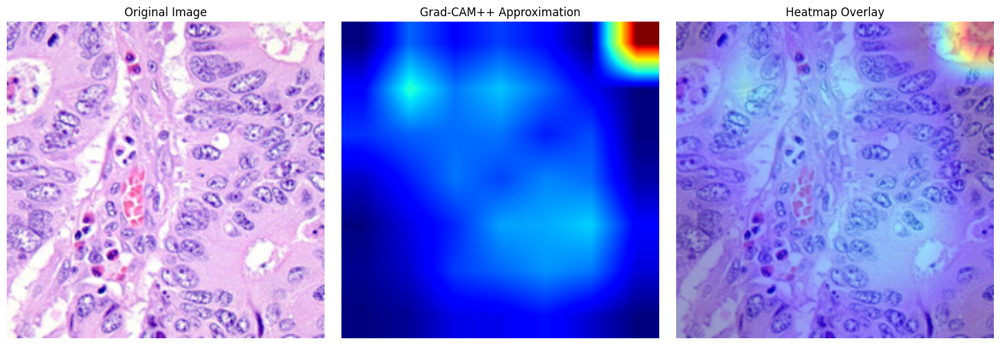

In [13]:

# Generate the heatmap
heatmap, pred = gradcampp_approx(
    effnet_model,
    effnet_base,
    image_tensor
)

print("Heatmap shape:", heatmap.shape)
print("Heatmap minimum:", heatmap.min())
print("Heatmap maximum:", heatmap.max())
print("All values finite:", np.isfinite(heatmap).all())

# Load original image for display
with Image.open(image_path) as img:
    original = img.convert("RGB").resize((224, 224))

# Resize heatmap to match image dimensions
heatmap_resized = tf.image.resize(
    heatmap[..., None],
    (224, 224),
    method="bilinear"
).numpy().squeeze()

# Display original, heatmap, and overlay
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original)
axes[0].set_title("Original Image")

axes[1].imshow(heatmap_resized, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM++ Approximation")

axes[2].imshow(original)
axes[2].imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.4,
    vmin=0,
    vmax=1
)
axes[2].set_title("Heatmap Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


I0000 00:00:1792424984.862233      49 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2026-10-19 15:49:47.472716: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-19 15:49:47.614706: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


EfficientNetB3 probabilities: [9.994894e-01 5.105552e-04]
ConvNeXt-Tiny probabilities: [9.9999893e-01 1.0776133e-06]


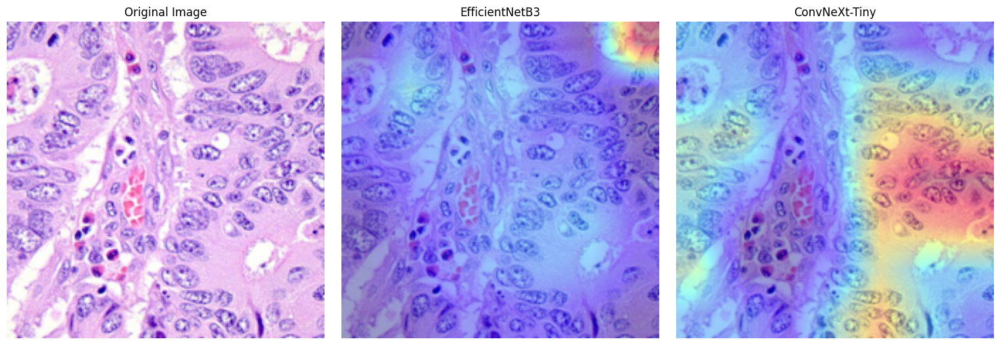

In [14]:

# Generate exploratory attribution heatmaps
effnet_heatmap, effnet_pred = gradcampp_approx(
    effnet_model,
    effnet_base,
    image_tensor
)

convnext_heatmap, convnext_pred = gradcampp_approx(
    convnext_model,
    convnext_base,
    image_tensor
)

# Resize both heatmaps to 224 x 224
def resize_heatmap(heatmap):
    return tf.image.resize(
        heatmap[..., None],
        (224, 224),
        method="bilinear"
    ).numpy().squeeze()

effnet_resized = resize_heatmap(effnet_heatmap)
convnext_resized = resize_heatmap(convnext_heatmap)

# Compare predictions
print("EfficientNetB3 probabilities:", effnet_pred[0])
print("ConvNeXt-Tiny probabilities:", convnext_pred[0])

# Display side-by-side overlays
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original)
axes[0].set_title("Original Image")

axes[1].imshow(original)
axes[1].imshow(
    effnet_resized,
    cmap="jet",
    alpha=0.4,
    vmin=0,
    vmax=1
)
axes[1].set_title("EfficientNetB3")

axes[2].imshow(original)
axes[2].imshow(
    convnext_resized,
    cmap="jet",
    alpha=0.4,
    vmin=0,
    vmax=1
)
axes[2].set_title("ConvNeXt-Tiny")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


### Comparing Exploratory Heatmaps

The exploratory heatmaps appeared to highlight different regions, so I calculated their spatial correlation for one image. This described similarity between the two maps, but did not establish which explanation was more accurate or clinically meaningful.

In [15]:

import numpy as np

# Flatten the original 7x7 attribution maps
effnet_flat = effnet_heatmap.flatten()
convnext_flat = convnext_heatmap.flatten()

# Calculate spatial correlation
spatial_correlation = np.corrcoef(
    effnet_flat,
    convnext_flat
)[0, 1]

print(
    "Spatial attribution correlation:",
    round(float(spatial_correlation), 4)
)

print("\nEfficientNetB3 heatmap:")
print("Mean:", round(float(effnet_heatmap.mean()), 4))
print("Std:", round(float(effnet_heatmap.std()), 4))

print("\nConvNeXt-Tiny heatmap:")
print("Mean:", round(float(convnext_heatmap.mean()), 4))
print("Std:", round(float(convnext_heatmap.std()), 4))


Spatial attribution correlation: -0.0352

EfficientNetB3 heatmap:
Mean: 0.1686
Std: 0.1577

ConvNeXt-Tiny heatmap:
Mean: 0.3659
Std: 0.2635


## 4. Final Grad-CAM++ Implementation

I revised the attribution function to use an exponentiated pre-softmax logit and the structure of each saved classification head. I then checked that the resulting heatmaps contained finite values and spatial variation before continuing with the evaluation.

The implementation was specific to these saved models and should not be assumed to work unchanged for other architectures.

In [16]:

def gradcampp(model, backbone, image_tensor, class_index=None):
    """
    Grad-CAM++ using an exponentiated pre-softmax logit.

    Valid for our saved models' piecewise-linear
    classification heads after the backbone.
    """
    final_dense = model.layers[-1]

    with tf.GradientTape() as tape:
        # Input rescaling and pretrained backbone
        x = model.layers[1](image_tensor)
        feature_maps = backbone(x, training=False)
        tape.watch(feature_maps)

        # Classification head, excluding final softmax
        x = feature_maps
        for layer in model.layers[3:-1]:
            x = layer(x, training=False)

        # Calculate logits directly using the saved
        # final Dense layer's weights and bias
        logits = tf.matmul(x, final_dense.kernel)
        logits = tf.nn.bias_add(logits, final_dense.bias)

        probabilities = tf.nn.softmax(logits)

        if class_index is None:
            class_index = int(
                tf.argmax(probabilities[0]).numpy()
            )

        class_logit = logits[:, class_index]

    # First derivative of the class logit
    grads = tape.gradient(class_logit, feature_maps)

    if grads is None:
        raise ValueError("Gradients could not be computed.")

    activations = feature_maps[0]
    grads = grads[0]

    # For exp(logit), second and third derivatives
    # are proportional to grads**2 and grads**3
    # because the head is locally affine.
    grads_sq = tf.square(grads)
    grads_cube = grads_sq * grads

    sum_activations = tf.reduce_sum(
        activations, axis=(0, 1), keepdims=True
    )

    denominator = (
        2.0 * grads_sq
        + sum_activations * grads_cube
    )

    alphas = tf.math.divide_no_nan(
        grads_sq, denominator
    )

    # Spatially weighted positive derivatives
    weights = tf.reduce_sum(
        alphas * tf.nn.relu(grads),
        axis=(0, 1)
    )

    # Combine the feature maps
    heatmap = tf.reduce_sum(
        activations * weights,
        axis=-1
    )

    heatmap = tf.nn.relu(heatmap)
    heatmap = tf.math.divide_no_nan(
        heatmap, tf.reduce_max(heatmap)
    )

    return heatmap.numpy(), probabilities.numpy()



EfficientNetB3
Shape: (7, 7)
Minimum: 0.0
Maximum: 1.0
Standard deviation: 0.15606911
Finite: True

ConvNeXt-Tiny
Shape: (7, 7)
Minimum: 0.0
Maximum: 1.0
Standard deviation: 0.26811582
Finite: True

New spatial correlation: -0.08791720332803189


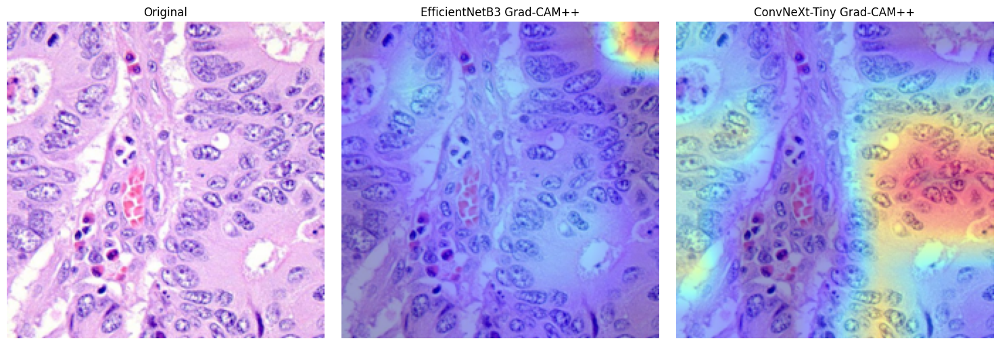

In [17]:

# Recalculate using the revised Grad-CAM++ implementation
effnet_cam, effnet_probs = gradcampp(
    effnet_model,
    effnet_base,
    image_tensor
)

convnext_cam, convnext_probs = gradcampp(
    convnext_model,
    convnext_base,
    image_tensor
)

# Check results
for name, cam in [
    ("EfficientNetB3", effnet_cam),
    ("ConvNeXt-Tiny", convnext_cam)
]:
    print(f"\n{name}")
    print("Shape:", cam.shape)
    print("Minimum:", cam.min())
    print("Maximum:", cam.max())
    print("Standard deviation:", cam.std())
    print("Finite:", np.isfinite(cam).all())

# Compare spatial correlation
if effnet_cam.std() > 0 and convnext_cam.std() > 0:
    correlation = np.corrcoef(
        effnet_cam.ravel(),
        convnext_cam.ravel()
    )[0, 1]
    print("\nNew spatial correlation:", correlation)

# Plot comparisons
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original)
axes[0].set_title("Original")

for ax, cam, title in [
    (axes[1], effnet_cam, "EfficientNetB3 Grad-CAM++"),
    (axes[2], convnext_cam, "ConvNeXt-Tiny Grad-CAM++")
]:
    resized = tf.image.resize(
        cam[..., None],
        (224, 224)
    ).numpy().squeeze()

    ax.imshow(original)
    ax.imshow(resized, cmap="jet", alpha=0.4, vmin=0, vmax=1)
    ax.set_title(title)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


### Visual Examples from Both Models

I generated revised Grad-CAM++ heatmaps for four selected test images to compare where the two models focused. Because a convincing-looking heatmap did not necessarily indicate a faithful explanation, I followed this with a quantitative analysis.

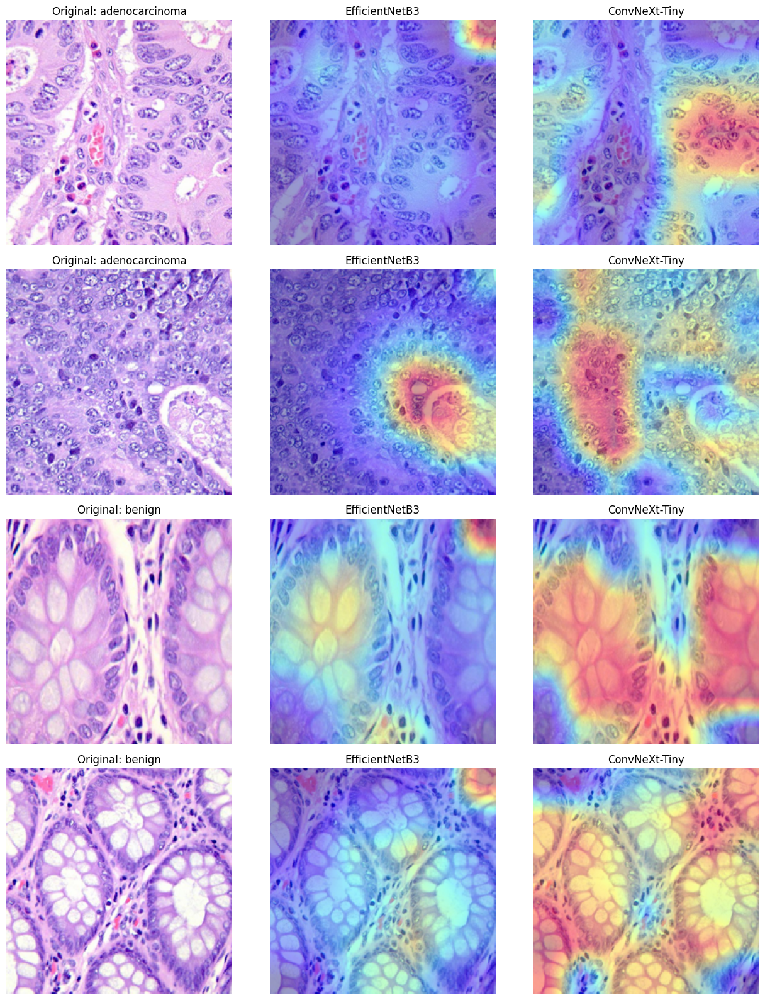

In [18]:

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from PIL import Image

# Store results for later analysis
xai_results = []

fig, axes = plt.subplots(
    len(sample_df),
    3,
    figsize=(13, 4 * len(sample_df))
)

class_names = ["adenocarcinoma", "benign"]

for i, row in sample_df.iterrows():

    filepath = row["filepaths"]
    true_label = row["labels"]

    # Load image using our existing preprocessing
    img_tensor = load_image_for_xai(filepath)

    with Image.open(filepath) as img:
        original_img = img.convert("RGB").resize((224, 224))

    # Generate Grad-CAM++ heatmaps
    eff_cam, eff_probs = gradcampp(
        effnet_model,
        effnet_base,
        img_tensor
    )

    conv_cam, conv_probs = gradcampp(
        convnext_model,
        convnext_base,
        img_tensor
    )

    # Resize heatmaps
    eff_resized = resize_heatmap(eff_cam)
    conv_resized = resize_heatmap(conv_cam)

    # Calculate spatial correlation
    if eff_cam.std() > 0 and conv_cam.std() > 0:
        correlation = np.corrcoef(
            eff_cam.flatten(),
            conv_cam.flatten()
        )[0, 1]
    else:
        correlation = np.nan

    # Save information
    xai_results.append({
        "filepath": filepath,
        "true_label": true_label,
        "effnet_pred": class_names[np.argmax(eff_probs[0])],
        "convnext_pred": class_names[np.argmax(conv_probs[0])],
        "spatial_correlation": correlation
    })

    # Original image
    axes[i, 0].imshow(original_img)
    axes[i, 0].set_title(f"Original: {true_label}")

    # EfficientNetB3 overlay
    axes[i, 1].imshow(original_img)
    axes[i, 1].imshow(
        eff_resized,
        cmap="jet",
        alpha=0.4,
        vmin=0,
        vmax=1
    )
    axes[i, 1].set_title("EfficientNetB3")

    # ConvNeXt-Tiny overlay
    axes[i, 2].imshow(original_img)
    axes[i, 2].imshow(
        conv_resized,
        cmap="jet",
        alpha=0.4,
        vmin=0,
        vmax=1
    )
    axes[i, 2].set_title("ConvNeXt-Tiny")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()

plt.savefig(
    "/kaggle/working/gradcampp_four_images.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [19]:

import pandas as pd

xai_df = pd.DataFrame(xai_results)

display(xai_df[
    [
        "true_label",
        "effnet_pred",
        "convnext_pred",
        "spatial_correlation"
    ]
].round(4))

print(
    "\nMean spatial correlation:",
    xai_df["spatial_correlation"].mean()
)

xai_df.to_csv(
    "/kaggle/working/gradcampp_sample_results.csv",
    index=False
)


,true_label,effnet_pred,convnext_pred,spatial_correlation
0,adenocarcinoma,adenocarcinoma,adenocarcinoma,-0.0879
1,adenocarcinoma,adenocarcinoma,adenocarcinoma,-0.0260
2,benign,benign,benign,0.1616
3,benign,benign,benign,0.3278



Mean spatial correlation: 0.09385707729336577


## 5. Developing the Faithfulness Evaluation

I used a balanced sample from the **validation partition** to develop the masking and faithfulness evaluation, leaving the test partition out of these decisions. I measured how prediction confidence changed when the regions highlighted by Grad-CAM++ were retained or removed.

In [20]:

# Load validation metadata for method development
validation_df = pd.read_csv(
    SPLIT_DIR / "validation.csv"
)

faithfulness_sample = (
    validation_df.groupby("labels", group_keys=False)
    .sample(n=2, random_state=40)
    .reset_index(drop=True)
)

print(faithfulness_sample["labels"].value_counts())

for filepath in faithfulness_sample["filepaths"]:
    assert Path(filepath).exists()

print("Validation sample ready.")


labels
adenocarcinoma    2
benign            2
Name: count, dtype: int64
Validation sample ready.


### Retaining Salient Regions

I resized each heatmap to the image dimensions and initially retained the 25% most salient pixels. I used a fixed retention percentage to compare the models under the same masking conditions.

In [21]:

def retain_salient_regions(image_tensor, heatmap, fraction=0.25):

    # Resize heatmap to match the input image
    heatmap_resized = tf.image.resize(
        heatmap[None, ..., None],
        (224, 224),
        method="bilinear"
    )

    # Select the highest-attribution pixels
    values = tf.reshape(heatmap_resized, [-1])
    threshold = tf.sort(values)[
        int((1.0 - fraction) * (values.shape[0] - 1))
    ]

    mask = tf.cast(
        heatmap_resized >= threshold,
        tf.float32
    )

    # Blur the image to create a reference background
    blurred = tf.nn.avg_pool2d(
        image_tensor,
        ksize=15,
        strides=1,
        padding="SAME"
    )

    # Keep salient regions clear and blur the rest
    retained = (
        image_tensor * mask
        + blurred * (1.0 - mask)
    )

    return retained, mask


Original confidence: 0.9998974800109863
Retained confidence: 0.9989559650421143
Confidence difference: -0.0009415149688720703


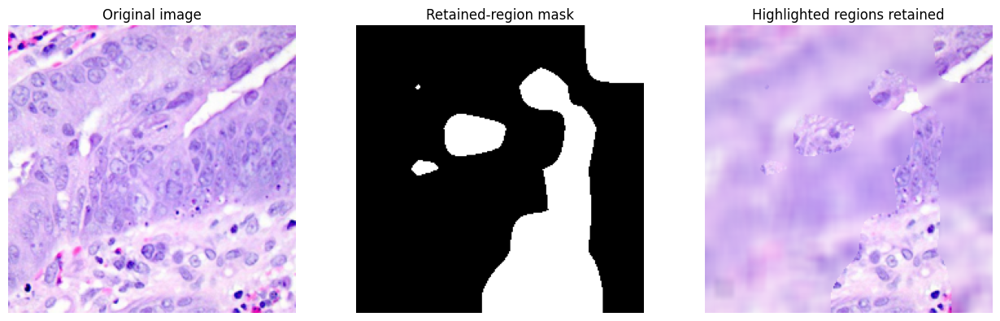

In [22]:

# Load first validation image
filepath = faithfulness_sample["filepaths"].iloc[0]
img_tensor = load_image_for_xai(filepath)

# Generate attribution
cam, original_probs = gradcampp(
    effnet_model,
    effnet_base,
    img_tensor
)

# Retain highlighted regions
retained_img, mask = retain_salient_regions(
    img_tensor,
    cam,
    fraction=0.25
)

# Predict on modified image
retained_probs = effnet_model(
    retained_img,
    training=False
).numpy()

# Class whose prediction we are explaining
class_idx = int(np.argmax(original_probs[0]))

original_confidence = float(original_probs[0, class_idx])
retained_confidence = float(retained_probs[0, class_idx])

print("Original confidence:", original_confidence)
print("Retained confidence:", retained_confidence)
print("Confidence difference:",
      retained_confidence - original_confidence)

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(img_tensor[0])
axes[0].set_title("Original image")

axes[1].imshow(mask[0, ..., 0], cmap="gray")
axes[1].set_title("Retained-region mask")

axes[2].imshow(retained_img[0])
axes[2].set_title("Highlighted regions retained")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


Fraction of pixels retained: 0.25
Original confidence: 0.999897
Grad-CAM++ retained: 0.998956
Random retained: 0.998971


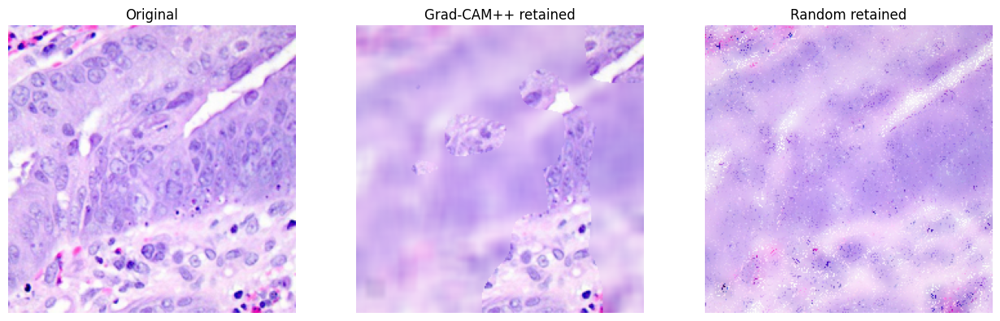

In [23]:

# Measure the actual retained fraction
retained_fraction = float(tf.reduce_mean(mask))

print(
    "Fraction of pixels retained:",
    round(retained_fraction, 4)
)

# Create a random mask with the same number of retained pixels
rng = np.random.default_rng(40)

mask_shape = mask.shape
total_pixels = int(np.prod(mask_shape[1:3]))
num_retained = int(round(retained_fraction * total_pixels))

random_values = np.zeros(total_pixels, dtype=np.float32)

selected_indices = rng.choice(
    total_pixels,
    size=num_retained,
    replace=False
)

random_values[selected_indices] = 1.0

random_mask = tf.convert_to_tensor(
    random_values.reshape(mask_shape),
    dtype=tf.float32
)

# Use the same blurred background
blurred = tf.nn.avg_pool2d(
    img_tensor,
    ksize=15,
    strides=1,
    padding="SAME"
)

random_retained = (
    img_tensor * random_mask
    + blurred * (1.0 - random_mask)
)

# Compare predictions
random_probs = effnet_model(
    random_retained,
    training=False
).numpy()

random_confidence = float(
    random_probs[0, class_idx]
)

print("Original confidence:", round(original_confidence, 6))
print("Grad-CAM++ retained:", round(retained_confidence, 6))
print("Random retained:", round(random_confidence, 6))

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].imshow(img_tensor[0])
axes[0].set_title("Original")

axes[1].imshow(retained_img[0])
axes[1].set_title("Grad-CAM++ retained")

axes[2].imshow(random_retained[0])
axes[2].set_title("Random retained")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


### Checking the Mask Against Alternative Regions

I inspected the retained regions alongside alternative masks before running the larger comparison. This helped me check the masking procedure, although the modified images were not equivalent to natural histopathology images.

Original confidence: 0.999897
Grad-CAM++ retained: 0.998956
Mean shifted-mask confidence: 0.997067
Minimum shifted-mask confidence: 0.977463
Maximum shifted-mask confidence: 0.999991
Grad-CAM++ outperformed 11 of 20 shifted masks


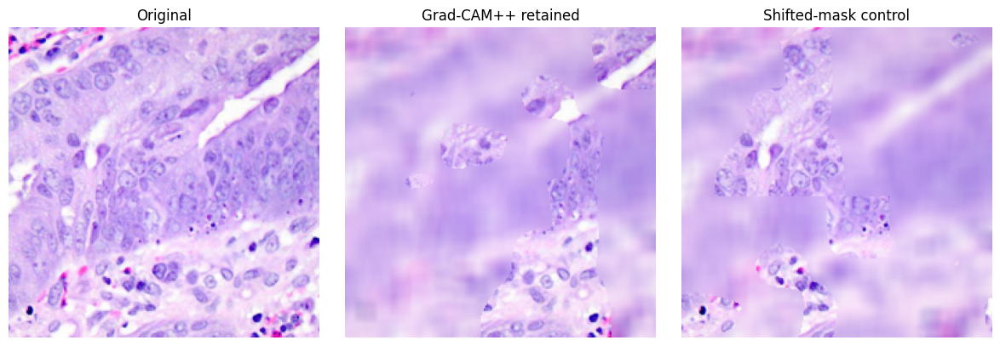

In [24]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(40)

# Existing variables:
# img_tensor, mask, effnet_model, class_idx

mask_np = mask.numpy()[0, :, :, 0]

# Create the same blurred background for every comparison
blurred = tf.nn.avg_pool2d(
    img_tensor,
    ksize=15,
    strides=1,
    padding="SAME"
)

shifted_results = []
example_shifted = None

for i in range(20):

    # Randomly shift the entire mask
    shift_y = int(rng.integers(28, 196))
    shift_x = int(rng.integers(28, 196))

    shifted_mask_np = np.roll(
        mask_np,
        shift=(shift_y, shift_x),
        axis=(0, 1)
    )

    shifted_mask = tf.convert_to_tensor(
        shifted_mask_np[None, :, :, None],
        dtype=tf.float32
    )

    # Apply the shifted mask
    shifted_image = (
        img_tensor * shifted_mask
        + blurred * (1.0 - shifted_mask)
    )

    # Predict the same original class
    shifted_probs = effnet_model(
        shifted_image,
        training=False
    ).numpy()

    confidence = float(
        shifted_probs[0, class_idx]
    )

    shifted_results.append(confidence)

    if i == 0:
        example_shifted = shifted_image.numpy()[0]

shifted_results = np.array(shifted_results)

print("Original confidence:", round(original_confidence, 6))
print("Grad-CAM++ retained:", round(retained_confidence, 6))
print("Mean shifted-mask confidence:",
      round(shifted_results.mean(), 6))
print("Minimum shifted-mask confidence:",
      round(shifted_results.min(), 6))
print("Maximum shifted-mask confidence:",
      round(shifted_results.max(), 6))

print(
    "Grad-CAM++ outperformed",
    int(np.sum(retained_confidence > shifted_results)),
    "of 20 shifted masks"
)

# Visualize one example
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(img_tensor[0])
axes[0].set_title("Original")

axes[1].imshow(retained_img[0])
axes[1].set_title("Grad-CAM++ retained")

axes[2].imshow(example_shifted)
axes[2].set_title("Shifted-mask control")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 6. Quantitative Faithfulness Metrics

I calculated **Average Drop %** to measure reductions in prediction confidence and **Increase in Confidence** to record how often confidence rose after salient regions were retained. I also examined margin-based measures to compare model responses to masked images.

These metrics measured the models' responses to masking, not whether the highlighted tissue was clinically relevant.

In [25]:

import numpy as np
import pandas as pd

def get_prediction_metrics(model, image, class_idx):
    probs = model(image, training=False).numpy()[0]

    # Avoid log(0) caused by floating-point saturation
    p = np.clip(probs.astype(np.float64), 1e-12, 1.0)

    other_idx = 1 - class_idx

    margin = np.log(p[class_idx]) - np.log(p[other_idx])

    return {
        "Selected class probability": float(probs[class_idx]),
        "Logit margin": float(margin)
    }


conditions = {
    "Original": img_tensor,
    "Grad-CAM++ retained": retained_img,
    "Random retained": random_retained
}

comparison = []

for name, image in conditions.items():
    metrics = get_prediction_metrics(
        effnet_model,
        image,
        class_idx
    )

    comparison.append({
        "Condition": name,
        **metrics
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(6))


,Condition,Selected class probability,Logit margin
0,Original,0.999897,9.185945
1,Grad-CAM++ retained,0.998956,6.863623
2,Random retained,0.998971,6.877766


### Evaluation Sample

I selected 20 validation images from each class, giving 40 unique images evaluated by both models. I used the same images for a paired comparison, so the results represented this sample rather than the full dataset.

In [26]:

# Select 20 validation images from each class
evaluation_df = (
    validation_df.groupby("labels", group_keys=False)
    .sample(n=20, random_state=40)
    .reset_index(drop=True)
)

print("Evaluation images:", len(evaluation_df))
print(evaluation_df["labels"].value_counts())


Evaluation images: 40
labels
adenocarcinoma    20
benign            20
Name: count, dtype: int64


In [27]:

def evaluate_faithfulness(model, backbone, filepath, fraction=0.25):

    image = load_image_for_xai(filepath)

    # Generate Grad-CAM++ for the predicted class
    cam, probabilities = gradcampp(
        model, backbone, image
    )

    class_idx = int(np.argmax(probabilities[0]))
    p_original = float(probabilities[0, class_idx])

    # Keep highlighted areas, blur everything else
    retained, mask = retain_salient_regions(
        image, cam, fraction=fraction
    )

    # Remove highlighted areas, blur those locations
    blurred = tf.nn.avg_pool2d(
        image, ksize=15, strides=1, padding="SAME"
    )

    deleted = (
        image * (1.0 - mask)
        + blurred * mask
    )

    # Model predictions after both interventions
    p_retained_all = model(
        retained, training=False
    ).numpy()[0]

    p_deleted_all = model(
        deleted, training=False
    ).numpy()[0]

    p_retained = float(p_retained_all[class_idx])

    # Average Drop % (per-image contribution)
    average_drop = (
        max(0.0, p_original - p_retained)
        / max(p_original, 1e-12)
        * 100.0
    )

    # Increase in Confidence indicator
    confidence_increase = int(p_retained > p_original)

    # Logit margin from binary probabilities
    # Avoid taking log(0)
    def margin(probs):
        probs = np.clip(
            np.asarray(probs, dtype=np.float64),
            1e-12, 1.0
        )
        other_idx = 1 - class_idx
        return float(
            np.log(probs[class_idx])
            - np.log(probs[other_idx])
        )

    original_margin = margin(probabilities[0])
    retained_margin = margin(p_retained_all)
    deleted_margin = margin(p_deleted_all)

    return {
        "class_idx": class_idx,
        "original_confidence": p_original,
        "retained_confidence": p_retained,
        "average_drop_pct": average_drop,
        "confidence_increase": confidence_increase,
        "retention_margin_drop": (
            original_margin - retained_margin
        ),
        "deletion_margin_drop": (
            original_margin - deleted_margin
        ),
        "retained_fraction": float(
            tf.reduce_mean(mask).numpy()
        )
    }


In [28]:

from tqdm.auto import tqdm

model_configs = {
    "EfficientNetB3": (effnet_model, effnet_base),
    "ConvNeXt-Tiny": (convnext_model, convnext_base)
}

all_results = []

for model_name, (model, backbone) in model_configs.items():

    print(f"\nEvaluating {model_name}...")

    for _, row in tqdm(
        evaluation_df.iterrows(),
        total=len(evaluation_df)
    ):

        metrics = evaluate_faithfulness(
            model,
            backbone,
            row["filepaths"],
            fraction=0.25
        )

        all_results.append({
            "model": model_name,
            "filepath": row["filepaths"],
            "true_label": row["labels"],
            **metrics
        })

faithfulness_df = pd.DataFrame(all_results)

faithfulness_df.to_csv(
    "/kaggle/working/faithfulness_results_40.csv",
    index=False
)

print("Evaluation complete.")
print("Rows:", len(faithfulness_df))



Evaluating EfficientNetB3...


  0%|          | 0/40 [00:00<?, ?it/s]


Evaluating ConvNeXt-Tiny...


  0%|          | 0/40 [00:00<?, ?it/s]

Evaluation complete.
Rows: 80


## 7. Results: Retaining 25% of Each Image

With 25% of each image retained, EfficientNetB3 had an Average Drop of approximately **9.70%**, compared with **27.05%** for ConvNeXt-Tiny. Confidence increased for **12.5%** and **2.5%** of images, respectively.

EfficientNetB3 retained more of its original prediction confidence in this experiment, but this did not establish that its heatmaps identified more clinically meaningful features.

In [29]:

summary_df = faithfulness_df.groupby("model").agg(
    images=("filepath", "count"),
    avg_drop_pct=("average_drop_pct", "mean"),
    increase_pct=("confidence_increase", "mean"),
    retention_margin_drop=("retention_margin_drop", "mean"),
    deletion_margin_drop=("deletion_margin_drop", "mean"),
    retained_fraction=("retained_fraction", "mean")
)

summary_df["increase_pct"] *= 100

display(summary_df.round(4))

summary_df.to_csv(
    "/kaggle/working/faithfulness_summary_40.csv"
)


,images,avg_drop_pct,increase_pct,retention_margin_drop,deletion_margin_drop,retained_fraction
model,,,,,,
ConvNeXt-Tiny,40,27.0535,2.5,12.1765,9.2909,0.25
EfficientNetB3,40,9.7026,12.5,7.4847,6.6467,0.25


### Differences Between Benign and Adenocarcinoma Images

The average confidence drops differed between classes. Both models showed relatively small drops for adenocarcinoma images, while drops were larger for benign images, particularly with ConvNeXt-Tiny. I therefore reported class-specific results alongside the overall averages.

In [30]:

# Compare faithfulness metrics separately by tissue class

class_summary = (
    faithfulness_df
    .groupby(["model", "true_label"])
    .agg(
        images=("filepath", "count"),
        avg_drop_pct=("average_drop_pct", "mean"),
        increase_pct=("confidence_increase", "mean"),
        retention_margin_drop=("retention_margin_drop", "mean"),
        deletion_margin_drop=("deletion_margin_drop", "mean")
    )
)

class_summary["increase_pct"] *= 100

display(class_summary.round(4))


images  avg_drop_pct  increase_pct  \
model          true_label                                           
ConvNeXt-Tiny  adenocarcinoma      20        0.5139           5.0   
               benign              20       53.5932           0.0   
EfficientNetB3 adenocarcinoma      20        0.2615          25.0   
               benign              20       19.1438           0.0   

                               retention_margin_drop  deletion_margin_drop  
model          true_label                                                   
ConvNeXt-Tiny  adenocarcinoma                 7.9201                8.8279  
               benign                        16.4329                9.7540  
EfficientNetB3 adenocarcinoma                 3.8597                3.6685  
               benign                        11.1096                9.6248

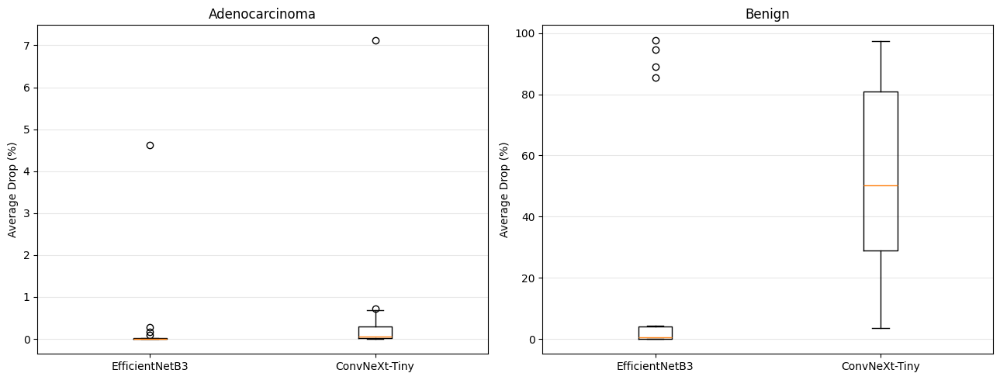

median    min     max     std
model          true_label                                   
ConvNeXt-Tiny  adenocarcinoma   0.063  0.000   7.126   1.571
               benign          50.319  3.586  97.398  31.609
EfficientNetB3 adenocarcinoma   0.001  0.000   4.629   1.030
               benign           0.405  0.000  97.739  37.317

In [31]:

import matplotlib.pyplot as plt
import pandas as pd

# Compare per-image Average Drop % for each class
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, tissue_class in zip(
    axes, ["adenocarcinoma", "benign"]
):
    subset = faithfulness_df[
        faithfulness_df["true_label"] == tissue_class
    ]

    data = [
        subset.loc[
            subset["model"] == "EfficientNetB3",
            "average_drop_pct"
        ].values,
        subset.loc[
            subset["model"] == "ConvNeXt-Tiny",
            "average_drop_pct"
        ].values
    ]

    ax.boxplot(
        data,
        tick_labels=["EfficientNetB3", "ConvNeXt-Tiny"]
    )

    ax.set_title(tissue_class.capitalize())
    ax.set_ylabel("Average Drop (%)")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Median and maximum drop by model and class
distribution_summary = (
    faithfulness_df
    .groupby(["model", "true_label"])["average_drop_pct"]
    .agg(["median", "min", "max", "std"])
)

display(distribution_summary.round(3))


### Paired Comparison and Uncertainty

I compared the models' Average Drop scores on the same images and used bootstrap resampling to estimate uncertainty. The overall mean difference was approximately **17.35 percentage points** in favour of EfficientNetB3, but the difference was larger for benign images. I treated these results as exploratory because each class contained only 20 images.

In [32]:

import numpy as np
import pandas as pd

# Put the two models side by side for each image
paired_df = faithfulness_df.pivot(
    index=["filepath", "true_label"],
    columns="model",
    values="average_drop_pct"
).dropna()

# Positive = EfficientNetB3 has lower Average Drop %
paired_df["difference"] = (
    paired_df["ConvNeXt-Tiny"]
    - paired_df["EfficientNetB3"]
)

rng = np.random.default_rng(40)

def bootstrap_mean_ci(values, n_boot=5000):
    values = np.asarray(values, dtype=float)

    sample_indices = rng.integers(
        0, len(values),
        size=(n_boot, len(values))
    )

    bootstrap_means = values[sample_indices].mean(axis=1)

    return np.percentile(
        bootstrap_means,
        [2.5, 97.5]
    )

# Overall and class-specific paired comparisons
rows = []

for label, group in [
    ("Overall", paired_df),
    ("Adenocarcinoma", paired_df.xs(
        "adenocarcinoma", level="true_label"
    )),
    ("Benign", paired_df.xs(
        "benign", level="true_label"
    ))
]:
    differences = group["difference"].to_numpy()

    ci_lower, ci_upper = bootstrap_mean_ci(differences)

    rows.append({
        "Class": label,
        "Images": len(differences),
        "Mean difference (pp)": differences.mean(),
        "Median difference (pp)": np.median(differences),
        "95% bootstrap lower": ci_lower,
        "95% bootstrap upper": ci_upper,
        "EffNet lower drop (%)": 100 * np.mean(
            differences > 0
        )
    })

paired_summary = pd.DataFrame(rows)

display(paired_summary.round(3))


,Class,Images,Mean difference (pp),Median difference (pp),95% bootstrap lower,95% bootstrap upper,EffNet lower drop (%)
0,Overall,40,17.351,0.332,4.987,30.439,85.0
1,Adenocarcinoma,20,0.252,0.059,0.061,0.524,90.0
2,Benign,20,34.449,40.511,11.003,56.769,80.0


## 8. Shifted-Mask Controls

I compared each Grad-CAM++ mask with shifted versions of that mask to test whether the highlighted regions preserved more confidence than alternative regions. These controls provided context, although masking itself could still affect the models' predictions.

In [33]:

def evaluate_shifted_controls(
    model, backbone, filepath,
    n_controls=10, fraction=0.25, seed=40
):
    rng = np.random.default_rng(seed)

    image = load_image_for_xai(filepath)

    # Generate Grad-CAM++
    cam, probabilities = gradcampp(
        model, backbone, image
    )

    class_idx = int(np.argmax(probabilities[0]))

    # Retain the regions highlighted by Grad-CAM++
    retained, mask = retain_salient_regions(
        image, cam, fraction=fraction
    )

    cam_confidence = float(
        model(retained, training=False).numpy()[0, class_idx]
    )

    # Prepare blurred background
    blurred = tf.nn.avg_pool2d(
        image, ksize=15, strides=1, padding="SAME"
    )

    mask_np = mask.numpy()[0, :, :, 0]
    shifted_images = []

    for _ in range(n_controls):
        shift_y = int(rng.integers(1, 224))
        shift_x = int(rng.integers(1, 224))

        shifted_mask_np = np.roll(
            mask_np,
            shift=(shift_y, shift_x),
            axis=(0, 1)
        )

        shifted_mask = tf.convert_to_tensor(
            shifted_mask_np[None, :, :, None],
            dtype=tf.float32
        )

        shifted_image = (
            image * shifted_mask
            + blurred * (1.0 - shifted_mask)
        )

        shifted_images.append(shifted_image)

    # Evaluate controls in one batch
    controls_batch = tf.concat(shifted_images, axis=0)

    control_probs = model(
        controls_batch,
        training=False
    ).numpy()[:, class_idx]

    return {
        "cam_confidence": cam_confidence,
        "control_confidence": float(control_probs.mean()),
        "cam_advantage": float(
            cam_confidence - control_probs.mean()
        ),
        "win_rate": float(
            100 * np.mean(cam_confidence > control_probs)
        )
    }


In [34]:

from tqdm.auto import tqdm

control_results = []

for model_name, (model, backbone) in model_configs.items():
    print(f"\nEvaluating {model_name}...")

    for i, row in tqdm(
        evaluation_df.iterrows(),
        total=len(evaluation_df)
    ):
        metrics = evaluate_shifted_controls(
            model=model,
            backbone=backbone,
            filepath=row["filepaths"],
            n_controls=10,
            seed=40 + i
        )

        control_results.append({
            "model": model_name,
            "filepath": row["filepaths"],
            "true_label": row["labels"],
            **metrics
        })

controls_df = pd.DataFrame(control_results)

controls_df.to_csv(
    "/kaggle/working/shifted_mask_controls_40.csv",
    index=False
)

print("Completed:", len(controls_df), "rows")



Evaluating EfficientNetB3...


  0%|          | 0/40 [00:00<?, ?it/s]


Evaluating ConvNeXt-Tiny...


  0%|          | 0/40 [00:00<?, ?it/s]

2026-10-19 15:59:55.756870: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-19 15:59:55.892474: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


Completed: 80 rows


### Interpreting the Control Results

I compared confidence under Grad-CAM++ masks and shifted controls separately for benign and adenocarcinoma images. The differences were larger for benign images, which reinforced the importance of examining the classes separately.

In [35]:

control_summary = (
    controls_df
    .groupby(["model", "true_label"])
    .agg(
        images=("filepath", "count"),
        cam_confidence=("cam_confidence", "mean"),
        control_confidence=("control_confidence", "mean"),
        cam_advantage=("cam_advantage", "mean"),
        win_rate=("win_rate", "mean")
    )
)

display(control_summary.round(4))


images  cam_confidence  control_confidence  \
model          true_label                                                   
ConvNeXt-Tiny  adenocarcinoma      20          0.9947              0.9899   
               benign              20          0.4641              0.2655   
EfficientNetB3 adenocarcinoma      20          0.9974              0.9961   
               benign              20          0.8085              0.4373   

                               cam_advantage  win_rate  
model          true_label                               
ConvNeXt-Tiny  adenocarcinoma         0.0048      71.5  
               benign                 0.1985      74.0  
EfficientNetB3 adenocarcinoma         0.0013      64.5  
               benign                 0.3713      84.0

In [36]:

# Combine Average Drop and control-based results

drop_summary = (
    faithfulness_df
    .groupby(["model", "true_label"])
    .agg(
        avg_drop_pct=("average_drop_pct", "mean"),
        increase_pct=("confidence_increase", "mean")
    )
)

drop_summary["increase_pct"] *= 100

control_metrics = (
    controls_df
    .groupby(["model", "true_label"])
    .agg(
        cam_advantage=("cam_advantage", "mean"),
        control_win_rate=("win_rate", "mean")
    )
)

final_xai_summary = drop_summary.join(control_metrics)

display(final_xai_summary.round(4))

final_xai_summary.to_csv(
    "/kaggle/working/final_xai_summary.csv"
)


avg_drop_pct  increase_pct  cam_advantage  \
model          true_label                                                  
ConvNeXt-Tiny  adenocarcinoma        0.5139           5.0         0.0048   
               benign               53.5932           0.0         0.1985   
EfficientNetB3 adenocarcinoma        0.2615          25.0         0.0013   
               benign               19.1438           0.0         0.3713   

                               control_win_rate  
model          true_label                        
ConvNeXt-Tiny  adenocarcinoma              71.5  
               benign                      74.0  
EfficientNetB3 adenocarcinoma              64.5  
               benign                      84.0

## 9. Robustness Check: Retaining 50% of Each Image

I repeated the shifted-mask comparison while retaining 50% rather than 25% of each image. I wanted to see whether the results depended on how much of the image was preserved.

In [37]:

from tqdm.auto import tqdm

robustness_results = []

for model_name, (model, backbone) in model_configs.items():

    print(f"\nEvaluating {model_name} at 50% retention...")

    for i, row in tqdm(
        evaluation_df.iterrows(),
        total=len(evaluation_df)
    ):

        metrics = evaluate_shifted_controls(
            model=model,
            backbone=backbone,
            filepath=row["filepaths"],
            n_controls=10,
            fraction=0.50,
            seed=40 + i
        )

        robustness_results.append({
            "model": model_name,
            "filepath": row["filepaths"],
            "true_label": row["labels"],
            **metrics
        })

robustness_df = pd.DataFrame(robustness_results)

robustness_df.to_csv(
    "/kaggle/working/robustness_controls_50pct.csv",
    index=False
)

print("Completed:", len(robustness_df), "rows")



Evaluating EfficientNetB3 at 50% retention...


  0%|          | 0/40 [00:00<?, ?it/s]


Evaluating ConvNeXt-Tiny at 50% retention...


  0%|          | 0/40 [00:00<?, ?it/s]

Completed: 80 rows


In [38]:

robustness_summary = (
    robustness_df
    .groupby(["model", "true_label"])
    .agg(
        images=("filepath", "count"),
        cam_confidence=("cam_confidence", "mean"),
        control_confidence=("control_confidence", "mean"),
        cam_advantage=("cam_advantage", "mean"),
        win_rate=("win_rate", "mean")
    )
)

display(robustness_summary.round(4))


images  cam_confidence  control_confidence  \
model          true_label                                                   
ConvNeXt-Tiny  adenocarcinoma      20          0.9961              0.9763   
               benign              20          0.9679              0.8569   
EfficientNetB3 adenocarcinoma      20          0.9994              0.9984   
               benign              20          0.8933              0.7151   

                               cam_advantage  win_rate  
model          true_label                               
ConvNeXt-Tiny  adenocarcinoma         0.0197      81.5  
               benign                 0.1110      76.5  
EfficientNetB3 adenocarcinoma         0.0010      57.5  
               benign                 0.1782      72.0

## 10. Saving Outputs and Limitations

I saved the evaluation tables and figures so the results could be reviewed without rerunning the GPU analyses. I also created a ZIP backup of the main XAI outputs.

The evaluation had several limitations. It used a small validation sample, masking produced images that differed from the original training data, and the heatmaps did not establish clinical relevance. The dataset could also contain image relationships not identified by the similarity-grouping method from Notebook 01. For these reasons, I interpreted the findings as exploratory evidence about model behaviour on this dataset.

In [39]:

# Save the 50% robustness summary
robustness_summary.to_csv(
    "/kaggle/working/robustness_summary_50pct.csv"
)

print("Saved 50% robustness summary.")
print("Notebook 03 analysis complete.")


Saved 50% robustness summary.
Notebook 03 analysis complete.


### Project Summary

Both transfer-learning models performed well in Notebook 02, but their explanations behaved differently when salient regions were retained. EfficientNetB3 generally showed a smaller Average Drop in the validation sample, although the size of the difference depended on tissue class and masking conditions. The shifted-mask controls and 50% retention check helped assess those patterns, but did not confirm clinical relevance.

Together, the three notebooks documented dataset preparation, model training, and an evaluation of how the models responded to Grad-CAM++-based masking.

In [40]:

from pathlib import Path
import zipfile

working_dir = Path("/kaggle/working")
zip_path = working_dir / "colon_xai_results_backup.zip"

files_to_backup = [
    "gradcampp_four_images.png",
    "gradcampp_sample_results.csv",
    "faithfulness_results_40.csv",
    "faithfulness_summary_40.csv",
    "final_xai_summary.csv",
    "shifted_mask_controls_40.csv",
    "robustness_controls_50pct.csv",
    "robustness_summary_50pct.csv"
]

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in files_to_backup:
        filepath = working_dir / filename

        if filepath.exists():
            zipf.write(filepath, arcname=filename)
            print("Saved:", filename)
        else:
            print("MISSING:", filename)

print("\nBackup ZIP:", zip_path)
print(
    "Size:",
    round(zip_path.stat().st_size / (1024**2), 2),
    "MB"
)


Saved: gradcampp_four_images.png
Saved: gradcampp_sample_results.csv
Saved: faithfulness_results_40.csv
Saved: faithfulness_summary_40.csv
Saved: final_xai_summary.csv
Saved: shifted_mask_controls_40.csv
Saved: robustness_controls_50pct.csv
Saved: robustness_summary_50pct.csv

Backup ZIP: /kaggle/working/colon_xai_results_backup.zip
Size: 1.9 MB
